# <center>**Detecting Unusual Medicare Provider Billing Patterns**

### Project Overview

This project analyzes 2024 Medicare billing records published by the Centers for Medicare & Medicaid Services (CMS) to identify providers whose billing patterns stand out from others in the same specialty. The analysis focuses on Internal Medicine (93,627 providers) and Family Practice (83,639 providers), totaling 177,266 individual providers. Both are primary-care specialties with sufficiently large provider populations to support meaningful comparisons. Each specialty is analyzed separately so providers are compared with their peers. Flagged providers represent unusual billing patterns, not evidence of fraud.

### Research Questions

1. How do service volumes, charges, and payments vary within and between Internal Medicine and Family Practice?
2. Which billing indicators show the greatest variation among specialty peers?
3. Which providers are flagged, and how closely do they match outliers from a simpler statistical approach?
4. How could the results help analysts prioritize providers for review?


## **Data Preparation and Exploration**

In [1]:
# Import libraries for data analysis, visualization, and modeling

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel('ERROR')

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

print("Libraries loaded successfully.")

Libraries loaded successfully.


### Load and Inspect the Dataset

In [2]:
# Load the 2024 Medicare provider billing data and show the first few rows

df = pd.read_csv('Medicare_PHysician_Other_Practitioner_by_Provider_2024.csv', dtype={'Rndrng_NPI': str})

display(df.head(5))

,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,Bene_CC_PH_Diabetes_V2_Pct,Bene_CC_PH_HF_NonIHD_V2_Pct,Bene_CC_PH_Hyperlipidemia_V2_Pct,Bene_CC_PH_Hypertension_V2_Pct,Bene_CC_PH_IschemicHeart_V2_Pct,Bene_CC_PH_Osteoporosis_V2_Pct,Bene_CC_PH_Parkinson_V2_Pct,Bene_CC_PH_Arthritis_V2_Pct,Bene_CC_PH_Stroke_TIA_V2_Pct,Bene_Avg_Risk_Scre
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,48.0,48.0,75.0,75.0,51.0,18.0,4.0,63.0,21.0,2.5660
1,1003000530,Semonche,Amanda,M,DO,I,1021 Park Ave,Suite 203,Quakertown,PA,...,26.0,13.0,75.0,73.0,20.0,16.0,NaN,40.0,4.0,1.0811
2,1003000902,Lohano,Jaivanti,NaN,MD,I,2215 Portland Ave,NaN,Louisville,KY,...,28.0,10.0,75.0,75.0,25.0,9.0,NaN,45.0,5.0,0.9538
3,1003001256,Caragol,Jennifer,A,MD,I,2930 11th Ave,NaN,Evans,CO,...,30.0,29.0,61.0,71.0,30.0,18.0,NaN,52.0,NaN,1.9702
4,1003002379,Shrestha,Salona,NaN,MD,I,4805 Ne Glisan St,NaN,Portland,OR,...,33.0,51.0,67.0,75.0,38.0,26.0,NaN,42.0,15.0,2.5246


In [3]:
# Check dataset dimensions, columns, data types, missing values, and duplicates

print("Dataset shape:", df.shape)
df.info()

print("\nColumns:", df.columns.tolist())
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate NPIs:", df['Rndrng_NPI'].duplicated().sum())

Dataset shape: (177266, 81)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177266 entries, 0 to 177265
Data columns (total 81 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   Rndrng_NPI                        177266 non-null  object 
 1   Rndrng_Prvdr_Last_Org_Name        177266 non-null  object 
 2   Rndrng_Prvdr_First_Name           177266 non-null  object 
 3   Rndrng_Prvdr_MI                   113802 non-null  object 
 4   Rndrng_Prvdr_Crdntls              166881 non-null  object 
 5   Rndrng_Prvdr_Ent_Cd               177266 non-null  object 
 6   Rndrng_Prvdr_St1                  177266 non-null  object 
 7   Rndrng_Prvdr_St2                  37012 non-null   object 
 8   Rndrng_Prvdr_City                 177266 non-null  object 
 9   Rndrng_Prvdr_State_Abrvtn         177266 non-null  object 
 10  Rndrng_Prvdr_State_FIPS           177266 non-null  object 
 11  Rndrng_Prvdr_Zip5       

### Data Quality Checks

In [4]:
# Identify columns with missing values

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

display(pd.DataFrame({
    'Missing Count': missing,
    'Missing %': (missing / len(df) * 100).round(2)}))

,Missing Count,Missing %
Bene_Race_Othr_Cnt,148866,83.98
Drug_Sprsn_Ind,146714,82.76
Med_Sprsn_Ind,146714,82.76
Bene_Race_API_Cnt,146009,82.37
Rndrng_Prvdr_St2,140254,79.12
Bene_Race_Hspnc_Cnt,134354,75.79
Bene_CC_BH_PTSD_V1_Pct,129873,73.26
Bene_CC_BH_ADHD_OthCD_V1_Pct,128672,72.59
Bene_Race_Black_Cnt,122765,69.25
Bene_CC_BH_PD_V1_Pct,122217,68.95


In [5]:
# Check missing values in the 10 selected variables

essential = [
    'Rndrng_NPI',
    'Rndrng_Prvdr_Type',
    'Rndrng_Prvdr_State_Abrvtn',
    'Tot_Benes',
    'Tot_Srvcs',
    'Tot_HCPCS_Cds',
    'Tot_Sbmtd_Chrg',
    'Tot_Mdcr_Alowd_Amt',
    'Tot_Mdcr_Pymt_Amt',
    'Bene_Avg_Risk_Scre']

display(df[essential].isnull().sum().to_frame('Missing Values'))

,Missing Values
Rndrng_NPI,0
Rndrng_Prvdr_Type,0
Rndrng_Prvdr_State_Abrvtn,0
Tot_Benes,0
Tot_Srvcs,0
Tot_HCPCS_Cds,0
Tot_Sbmtd_Chrg,0
Tot_Mdcr_Alowd_Amt,0
Tot_Mdcr_Pymt_Amt,0
Bene_Avg_Risk_Scre,0


In [6]:
# Check numerical variables for zero and negative values

numeric_cols = [
    'Tot_Benes',
    'Tot_Srvcs',
    'Tot_HCPCS_Cds',
    'Tot_Sbmtd_Chrg',
    'Tot_Mdcr_Alowd_Amt',
    'Tot_Mdcr_Pymt_Amt',
    'Bene_Avg_Risk_Scre']

display(pd.DataFrame({
    'Zero Values': (df[numeric_cols] == 0).sum(),
    'Negative Values': (df[numeric_cols] < 0).sum()}))

,Zero Values,Negative Values
Tot_Benes,0,0
Tot_Srvcs,0,0
Tot_HCPCS_Cds,0,0
Tot_Sbmtd_Chrg,0,0
Tot_Mdcr_Alowd_Amt,0,0
Tot_Mdcr_Pymt_Amt,1,0
Bene_Avg_Risk_Scre,0,0


In [7]:
# Inspect the provider with zero Medicare payments (NPI hidden for privacy)

display(df.loc[df['Tot_Mdcr_Pymt_Amt'] == 0, essential].drop(columns='Rndrng_NPI'))

,Rndrng_Prvdr_Type,Rndrng_Prvdr_State_Abrvtn,Tot_Benes,Tot_Srvcs,Tot_HCPCS_Cds,Tot_Sbmtd_Chrg,Tot_Mdcr_Alowd_Amt,Tot_Mdcr_Pymt_Amt,Bene_Avg_Risk_Scre
143414,Family Practice,CA,16,16.0,3,3600.0,1683.09,0.0,1.5076


In [8]:
# Create a working dataset with the 10 selected variables

medicare = df[essential].copy()

print("Working dataset shape:", medicare.shape)

Working dataset shape: (177266, 10)


**Assessment: Data**

* **Data quality:** The dataset contains no duplicate rows or duplicate NPIs, and the 10 selected variables have no missing or negative values.
* **Missing values:** The 3,405,313 missing values across 60 columns occur mainly in demographic, chronic condition, drug-related, and address fields. Some drug-related fields used in the supplemental investigation also have missing or suppressed values, which were not treated as zeros.
* **Zero payment:** One Family Practice provider received `$0` in Medicare payments despite 16 beneficiaries and an allowed amount of `$1,683.09`. The record was kept because unusual billing is the focus of this analysis.

### Billing Totals by Specialty

In [9]:
# Summarize total billing amounts for each specialty

pd.set_option('display.float_format', '{:,.2f}'.format)

numeric = [
    'Tot_Benes',
    'Tot_Srvcs',
    'Tot_HCPCS_Cds',
    'Tot_Sbmtd_Chrg',
    'Tot_Mdcr_Alowd_Amt',
    'Tot_Mdcr_Pymt_Amt',
    'Bene_Avg_Risk_Scre']

for specialty in ['Internal Medicine', 'Family Practice']:
    print(f"\n{specialty}")
    display(medicare.loc[medicare['Rndrng_Prvdr_Type'] == specialty, numeric].describe().round(2))


Internal Medicine


,Tot_Benes,Tot_Srvcs,Tot_HCPCS_Cds,Tot_Sbmtd_Chrg,Tot_Mdcr_Alowd_Amt,Tot_Mdcr_Pymt_Amt,Bene_Avg_Risk_Scre
count,"93,627.00","93,627.00","93,627.00","93,627.00","93,627.00","93,627.00","93,627.00"
mean,244.03,"2,115.09",23.39,"269,866.34","108,635.34","84,572.24",1.89
std,365.23,"47,924.93",23.18,"876,437.22","620,678.06","494,213.89",0.85
min,11.00,11.00,1.00,80.44,62.27,48.87,0.43
25%,88.00,247.00,9.00,"60,041.24","23,605.78","17,900.79",1.16
50%,186.00,623.00,15.00,"151,782.00","58,078.20","44,569.13",1.76
75%,319.00,"1,370.00",31.00,"307,399.79","114,571.06","88,380.20",2.47
max,"67,125.00","12,429,889.00",317.00,"173,753,967.00","154,471,471.80","123,043,006.30",11.09



Family Practice


,Tot_Benes,Tot_Srvcs,Tot_HCPCS_Cds,Tot_Sbmtd_Chrg,Tot_Mdcr_Alowd_Amt,Tot_Mdcr_Pymt_Amt,Bene_Avg_Risk_Scre
count,"83,639.00","83,639.00","83,639.00","83,639.00","83,639.00","83,639.00","83,639.00"
mean,198.07,"1,546.65",33.34,"185,710.81","82,059.39","62,953.08",1.30
std,309.44,"8,558.69",26.44,"621,411.67","472,495.61","376,324.80",0.53
min,11.00,11.00,1.00,31.69,28.48,0.00,0.40
25%,68.00,201.00,14.00,"35,259.30","14,992.72","11,016.62",0.98
50%,147.00,568.00,27.00,"100,554.00","42,215.52","31,326.40",1.13
75%,262.00,"1,378.00",43.00,"216,306.75","89,954.24","68,081.92",1.43
max,"46,627.00","1,843,466.00",368.00,"108,015,799.00","102,478,786.00","81,646,546.97",7.49


**Assessment: Billing Totals by Specialty**

* **Typical billing:** Internal Medicine providers have higher typical payments and patient counts. The median Medicare payment is `$44,569` for Internal Medicine and `$31,326` for Family Practice, about 42% higher, and the median number of beneficiaries is 186 versus 147.
* **Procedure codes:** Family Practice providers bill a wider range of procedure codes, with a median of 27 distinct codes compared with 15 for Internal Medicine, suggesting a broader variety of billed services.
* **Patient complexity:** The median beneficiary risk score is 1.76 for Internal Medicine and 1.13 for Family Practice. This difference supports comparing providers only within their own specialty.
* **Extreme values:** Both specialties contain extreme values. The maximum number of services is about 12.4 million for Internal Medicine (median 623) and about 1.8 million for Family Practice (median 568). In every billing column, the mean is well above the median, indicating highly skewed distributions.

### Billing Indicators

In [10]:
# Calculate billing indicators for specialty comparisons

medicare['Services_Per_Bene'] = (
    medicare['Tot_Srvcs'] / medicare['Tot_Benes'])

medicare['Payments_Per_Bene'] = (
    medicare['Tot_Mdcr_Pymt_Amt'] / medicare['Tot_Benes'])

medicare['Charge_Allowed_Ratio'] = (
    medicare['Tot_Sbmtd_Chrg'] / medicare['Tot_Mdcr_Alowd_Amt'])

# Review the new indicators

display(medicare[
    ['Rndrng_Prvdr_Type', 'Services_Per_Bene',
     'Payments_Per_Bene', 'Charge_Allowed_Ratio']].head())

,Rndrng_Prvdr_Type,Services_Per_Bene,Payments_Per_Bene,Charge_Allowed_Ratio
0,Internal Medicine,1.22,107.70,4.36
1,Internal Medicine,4.65,350.59,1.58
2,Family Practice,3.59,252.07,1.97
3,Family Practice,1.65,97.10,4.45
4,Internal Medicine,3.18,279.15,3.39


In [11]:
# Summarize per-beneficiary billing indicators for each specialty

indicators = ['Services_Per_Bene', 'Payments_Per_Bene', 'Charge_Allowed_Ratio']

for specialty in ['Internal Medicine', 'Family Practice']:
    print(f"\n{specialty}")
    display(medicare.loc[medicare['Rndrng_Prvdr_Type'] == specialty, indicators].describe().round(2))


Internal Medicine


,Services_Per_Bene,Payments_Per_Bene,Charge_Allowed_Ratio
count,"93,627.00","93,627.00","93,627.00"
mean,7.85,326.70,2.88
std,265.45,"2,056.43",2.25
min,1.00,3.10,0.95
25%,2.30,163.63,1.92
50%,3.16,232.25,2.48
75%,5.28,332.45,3.27
max,"66,116.43","383,849.21",393.89



Family Practice


,Services_Per_Bene,Payments_Per_Bene,Charge_Allowed_Ratio
count,"83,639.00","83,639.00","83,639.00"
mean,6.44,316.83,2.64
std,18.73,"4,127.34",2.26
min,1.00,0.00,0.97
25%,2.38,132.18,1.83
50%,3.69,211.62,2.28
75%,6.36,310.63,2.90
max,"2,162.64","790,810.58",350.60


**Assessment: Per-Beneficiary Billing Indicators**

* **Size-adjusted comparison:** The 42% difference in median total Medicare payments narrows to about 10% when payments are measured per beneficiary, suggesting that differences in Medicare beneficiary counts contribute to the gap.
* **Services per beneficiary:** Family Practice has a higher median of 3.69 compared with 3.16 for Internal Medicine. Internal Medicine has the most extreme value, with a maximum of 66,116 services per beneficiary against a 75th percentile of 5.28; Family Practice reaches 2,163.
* **Payments per beneficiary:** Internal Medicine has a higher median of `$232.25` compared with `$211.62` for Family Practice. Family Practice has the most extreme value, with a maximum of `$790,811` per beneficiary against a 75th percentile of `$311`; Internal Medicine reaches `$383,849`.
* **Charge ratios:** Internal Medicine has a higher median submitted-to-allowed ratio of 2.48 compared with 2.28 for Family Practice, indicating higher submitted charges relative to Medicare allowed amounts. This indicator is the most contained, with maximums of about 394 and 351 against a 75th percentile of about 3. A few providers fall slightly below 1, meaning they charged less than Medicare allowed.
* **Skewness:** In every indicator, the mean is above the median, so the distributions remain heavily right-skewed even when measured per beneficiary. These extremes warrant further investigation but do not establish improper billing.

### Log Transformation

In [12]:
# Apply a log transformation to reduce skewness in the billing indicators

for col in indicators:
    medicare[f'Log_{col}'] = np.log1p(medicare[col])

log_indicators = [f'Log_{col}' for col in indicators]

# Compare skewness before and after for each specialty

before = medicare.groupby('Rndrng_Prvdr_Type')[indicators].skew().stack()
after = medicare.groupby('Rndrng_Prvdr_Type')[log_indicators].skew()
after.columns = indicators

skew_check = pd.DataFrame({'Before': before,'After': after.stack()})

display(skew_check.round(2))

Before  After
Rndrng_Prvdr_Type                                    
Family Practice   Services_Per_Bene      52.49   1.38
                  Payments_Per_Bene     125.18  -0.36
                  Charge_Allowed_Ratio   79.67   1.65
Internal Medicine Services_Per_Bene     217.59   2.08
                  Payments_Per_Bene     122.43   0.18
                  Charge_Allowed_Ratio   75.90   1.05

**Assessment: Billing Indicator Log Transformation**

* **Overall improvement:** The log transformation substantially reduced skewness across all three billing indicators in both specialties, making the distributions less dominated by extreme values.
* **Services per beneficiary:** Skewness dropped from 52.49 to 1.38 for Family Practice and from 217.59 to 2.08 for Internal Medicine. It remains the most right-skewed indicator in Internal Medicine after transformation.
* **Payments per beneficiary:** Skewness decreased from 125.18 to -0.36 for Family Practice and from 122.43 to 0.18 for Internal Medicine. Both distributions are now close to symmetric.
* **Charge ratios:** Skewness decreased from 79.67 to 1.65 for Family Practice and from 75.90 to 1.05 for Internal Medicine. It remains the most right-skewed indicator in Family Practice after transformation.
* **Remaining skewness:** Services per beneficiary and charge ratios remain right-skewed in both specialties, reflecting a small group of providers with unusually high values.

In [13]:
# Apply a log transformation to the beneficiary risk score and compare skewness for each specialty

medicare['Log_Bene_Avg_Risk_Scre'] = np.log1p(medicare['Bene_Avg_Risk_Scre'])

display(pd.DataFrame({
    'Before': medicare.groupby('Rndrng_Prvdr_Type')['Bene_Avg_Risk_Scre'].skew(),
    'After': medicare.groupby('Rndrng_Prvdr_Type')['Log_Bene_Avg_Risk_Scre'].skew()}).round(2))

,Before,After
Rndrng_Prvdr_Type,,
Family Practice,2.06,1.33
Internal Medicine,1.13,0.32


**Assessment: Risk Score Log Transformation**

* **Risk score skewness:** The log transformation reduced skewness from 1.13 to 0.32 for Internal Medicine, producing a nearly symmetric distribution, and from 2.06 to 1.33 for Family Practice, which remains moderately right-skewed.
* **Specialty difference:** Family Practice risk scores are more skewed than Internal Medicine scores both before and after transformation.

### Review Extreme Providers

In [14]:
# Examine extreme providers, including drug-related services and payments

measures = {
    'Services_Per_Bene': 'Highest Services/Bene',
    'Payments_Per_Bene': 'Highest Payments/Bene',
    'Charge_Allowed_Ratio': 'Highest Charge Ratio',
    'Bene_Avg_Risk_Scre': 'Highest Risk Score',
    'Tot_Srvcs': 'Highest Total Services'}
labels = {
    'Tot_Benes': 'Beneficiaries',
    'Tot_Srvcs': 'Total Services',
    'Drug_Tot_Srvcs': 'Drug Services',
    'Drug_Service_Share_%': 'Drug Services (%)',
    'Tot_HCPCS_Cds': 'Distinct Procedure Codes',
    'Tot_Sbmtd_Chrg': 'Submitted Charges ($)',
    'Tot_Mdcr_Alowd_Amt': 'Medicare Allowed ($)',
    'Tot_Mdcr_Pymt_Amt': 'Medicare Payments ($)',
    'Drug_Mdcr_Pymt_Amt': 'Drug Payments ($)',
    'Drug_Payment_Share_%': 'Drug Payments (%)',
    'Bene_Avg_Risk_Scre': 'Average Risk Score',
    'Services_Per_Bene': 'Services per Beneficiary',
    'Payments_Per_Bene': 'Payments per Beneficiary ($)',
    'Charge_Allowed_Ratio': 'Charge-to-Allowed Ratio'}
for specialty in ['Internal Medicine', 'Family Practice']:
    group = medicare[medicare['Rndrng_Prvdr_Type'] == specialty]
    rows = []
    for indicator, name in measures.items():
        idx = group[indicator].idxmax()
        record = medicare.loc[idx, [c for c in labels if c in medicare.columns]].to_dict()
        record['Drug_Tot_Srvcs'] = df.loc[idx, 'Drug_Tot_Srvcs']
        record['Drug_Mdcr_Pymt_Amt'] = df.loc[idx, 'Drug_Mdcr_Pymt_Amt']
        record['Drug_Service_Share_%'] = 100 * record['Drug_Tot_Srvcs'] / record['Tot_Srvcs']
        record['Drug_Payment_Share_%'] = 100 * record['Drug_Mdcr_Pymt_Amt'] / record['Tot_Mdcr_Pymt_Amt'] if record['Tot_Mdcr_Pymt_Amt'] > 0 else np.nan
        record['Extreme Measure'] = name
        rows.append(record)
    table = pd.DataFrame(rows).set_index('Extreme Measure')
    table = table[list(labels)].rename(columns=labels).T
    print(f"\n{specialty} — Extreme Provider Review")
    display(table.style.format('{:,.2f}', na_rep='Not reported'))


Internal Medicine — Extreme Provider Review


Extreme Measure,Highest Services/Bene,Highest Payments/Bene,Highest Charge Ratio,Highest Risk Score,Highest Total Services
Beneficiaries,188.00,39.00,55.00,15.00,188.00
Total Services,"12,429,889.00","10,109.00",56.00,65.00,"12,429,889.00"
Drug Services,"12,429,345.00",Not reported,0.00,0.00,"12,429,345.00"
Drug Services (%),100.00,Not reported,0.00,0.00,100.00
Distinct Procedure Codes,47.00,14.00,3.00,3.00,47.00
Submitted Charges ($),"31,593,983.20","20,293,895.00","2,953,136.12","22,688.35","31,593,983.20"
Medicare Allowed ($),"31,036,476.91","18,789,103.28","7,497.27","21,536.67","31,036,476.91"
Medicare Payments ($),"24,725,968.55","14,970,119.25","5,410.59","17,159.25","24,725,968.55"
Drug Payments ($),"24,705,635.30",Not reported,0.00,0.00,"24,705,635.30"
Drug Payments (%),99.92,Not reported,0.00,0.00,99.92



Family Practice — Extreme Provider Review


Extreme Measure,Highest Services/Bene,Highest Payments/Bene,Highest Charge Ratio,Highest Risk Score,Highest Total Services
Beneficiaries,75.00,12.00,17.00,32.00,"1,705.00"
Total Services,"162,198.00","4,641.00",17.00,144.00,"1,843,466.00"
Drug Services,"159,832.00",0.00,0.00,0.00,"1,834,305.00"
Drug Services (%),98.54,0.00,0.00,0.00,99.50
Distinct Procedure Codes,37.00,9.00,2.00,3.00,2.00
Submitted Charges ($),"399,384.60","13,338,220.94","745,350.00","38,596.00","13,205,670.00"
Medicare Allowed ($),"93,074.67","11,910,816.08","2,125.95","11,813.21","12,749,840.24"
Medicare Payments ($),"69,207.79","9,489,726.94","1,364.37","9,412.34","10,037,619.01"
Drug Payments ($),"3,758.71",0.00,0.00,0.00,"9,029,425.19"
Drug Payments (%),5.43,0.00,0.00,0.00,89.96


**Assessment: Extreme Providers**

* **Drug billing:** Drug units account for the most extreme service volumes. The Internal Medicine provider with the highest services per beneficiary and highest total services billed 12.4 million services, nearly 100% of which were drug services, accounting for 99.92% of `$24.7 million` in payments. The Family Practice provider with the highest total services had 99.5% drug services and 89.96% drug payments across only 2 procedure codes.
* **Unexplained payments:** The Family Practice provider with the highest payments per beneficiary received `$9.49 million` for 12 beneficiaries with no drug billing. The Internal Medicine provider with the highest payments per beneficiary received `$14.97 million` for 39 beneficiaries, but CMS did not report its drug data.
* **Charge ratios:** The highest charge ratios came from providers with few beneficiaries and no drug billing, submitting `$2.95 million` (Internal Medicine) and `$745,350` (Family Practice) in charges against allowed amounts of `$7,497` and `$2,126`.
* **Risk scores:** The highest risk scores (11.09 and 7.49) came from providers with only 15 and 32 Medicare beneficiaries, respectively. Both had modest billing and no reported drug services, consistent with highly complex patient populations.
* **Data validity:** No data errors were confirmed during this examination, so all providers were retained.

## **Data Visualization**

### VISUAL 1 - Histograms Showing How Billing Varies by Specialty

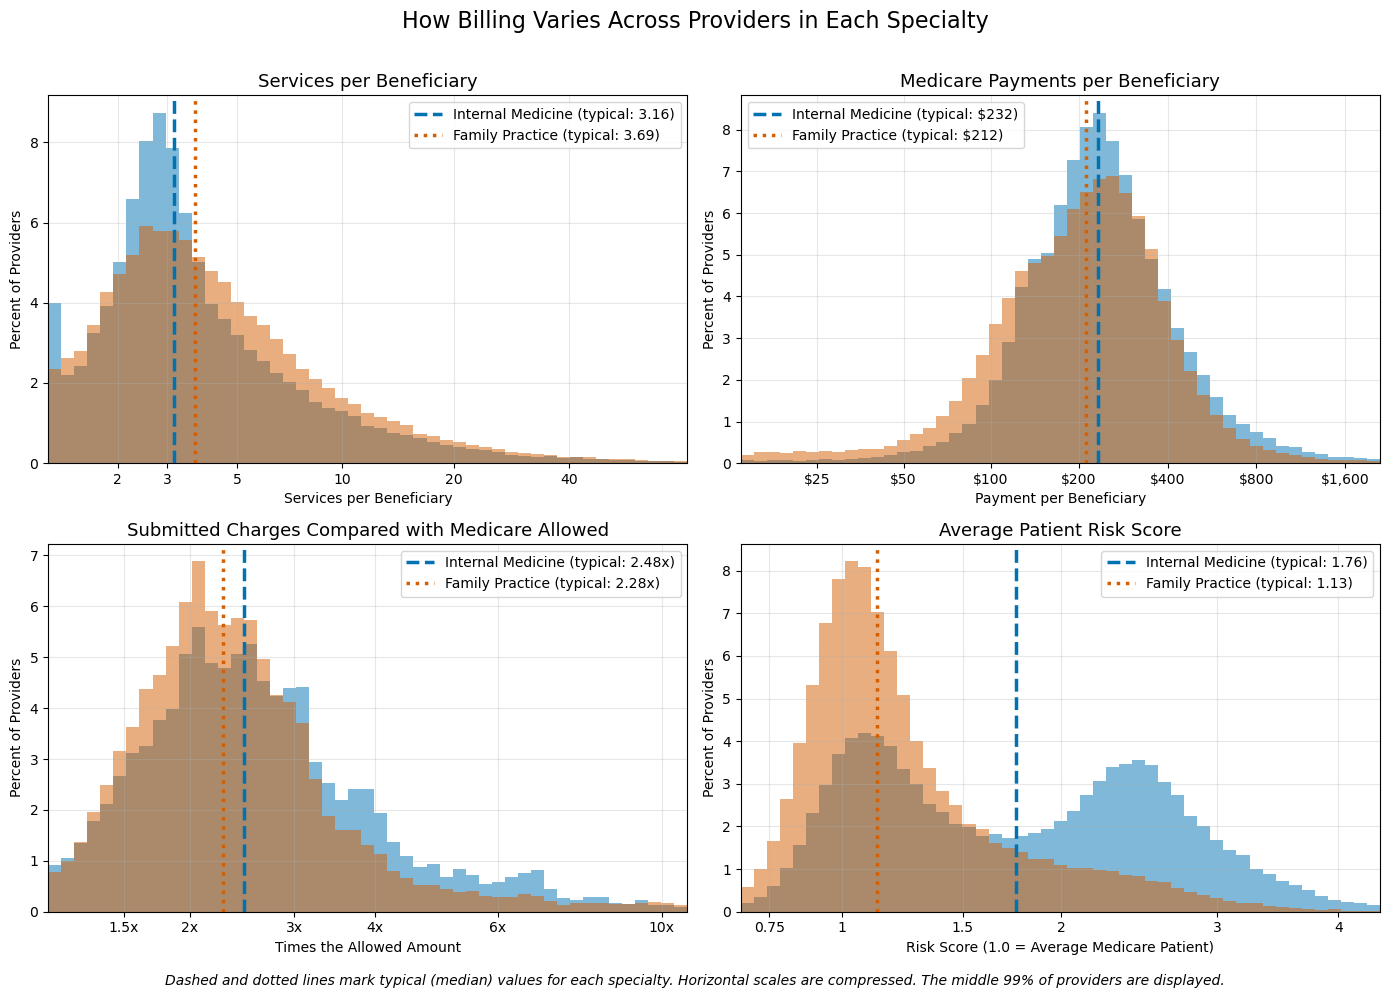

In [15]:
# Plot the distribution of each billing variable by specialty, showing the middle 99% of providers in real units

plots = {'Services_Per_Bene': ('Services per Beneficiary', 'Services per Beneficiary',
                          [1, 2, 3, 5, 10, 20, 40], lambda v: f'{v:,.0f}', lambda m: f'{m:.2f}'),
    'Payments_Per_Bene': ('Medicare Payments per Beneficiary', 'Payment per Beneficiary',
                          [25, 50, 100, 200, 400, 800, 1600], lambda v: f'${v:,.0f}', lambda m: f'${m:,.0f}'),
    'Charge_Allowed_Ratio': ('Submitted Charges Compared with Medicare Allowed', 'Times the Allowed Amount',
                             [1, 1.5, 2, 3, 4, 6, 10], lambda v: f'{v:g}x', lambda m: f'{m:.2f}x'),
    'Bene_Avg_Risk_Scre': ('Average Patient Risk Score', 'Risk Score (1.0 = Average Medicare Patient)',
                           [0.5, 0.75, 1, 1.5, 2, 3, 4], lambda v: f'{v:g}', lambda m: f'{m:.2f}')}

styles = {'Internal Medicine': ('#0072B2', '--'),
          'Family Practice': ('#D55E00', ':')}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (var, (title, xlabel, ticks, tick_fmt, median_fmt)) in zip(axes.flat, plots.items()):
    low, high = medicare[f'Log_{var}'].quantile([0.005, 0.995])
    for specialty, (color, line) in styles.items():
        group = medicare[medicare['Rndrng_Prvdr_Type'] == specialty]
        median = group[var].median()
        ax.hist(group[f'Log_{var}'], bins=np.linspace(low, high, 50), alpha=0.5, color=color,
                weights=np.ones(len(group)) / len(group) * 100)
        ax.axvline(np.log1p(median), color=color, linestyle=line, linewidth=2.5,
                   label=f'{specialty} (typical: {median_fmt(median)})')
    ticks = [t for t in ticks if low <= np.log1p(t) <= high]
    ax.set_xticks(np.log1p(ticks))
    ax.set_xticklabels([tick_fmt(t) for t in ticks])
    ax.set_xlim(low, high)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Percent of Providers')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

fig.suptitle('How Billing Varies Across Providers in Each Specialty', fontsize=16)
fig.text(0.5, 0.005,
         'Dashed and dotted lines mark typical (median) values for each specialty. Horizontal scales are compressed. '
         'The middle 99% of providers are displayed.',
         ha='center', fontsize=10, style='italic')

plt.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.show()

**Assessment: Visual 1**

* **Services per beneficiary:** Internal Medicine providers cluster more tightly around a typical 3.16 services per beneficiary, while Family Practice providers are more spread out, with a typical 3.69 and more providers billing 5 to 20 services per beneficiary.
* **Payments per beneficiary:** The two specialties overlap heavily, with typical payments of `$232` for Internal Medicine and `$212` for Family Practice. Family Practice has more providers at the low end, below `$100` per beneficiary.
* **Charge ratios:** Family Practice providers concentrate around 2 times the allowed amount (typical 2.28x), while Internal Medicine providers are more likely to submit 3 to 10 times the allowed amount (typical 2.48x).
* **Risk scores:** This is the largest difference between the specialties. Family Practice providers cluster near the average Medicare patient (typical 1.13), while Internal Medicine has two distinct groups: one near 1.0 and a second, larger group near 2.5, serving much more complex patients.
* **Overall:** The specialties show relatively similar typical billing indicators, but their patient risk-score distributions differ substantially, suggesting meaningful differences in patient complexity.

### VISUAL 2 - Heatmap Showing Relationships Among Billing Indicators and Risk Scores by Specialty

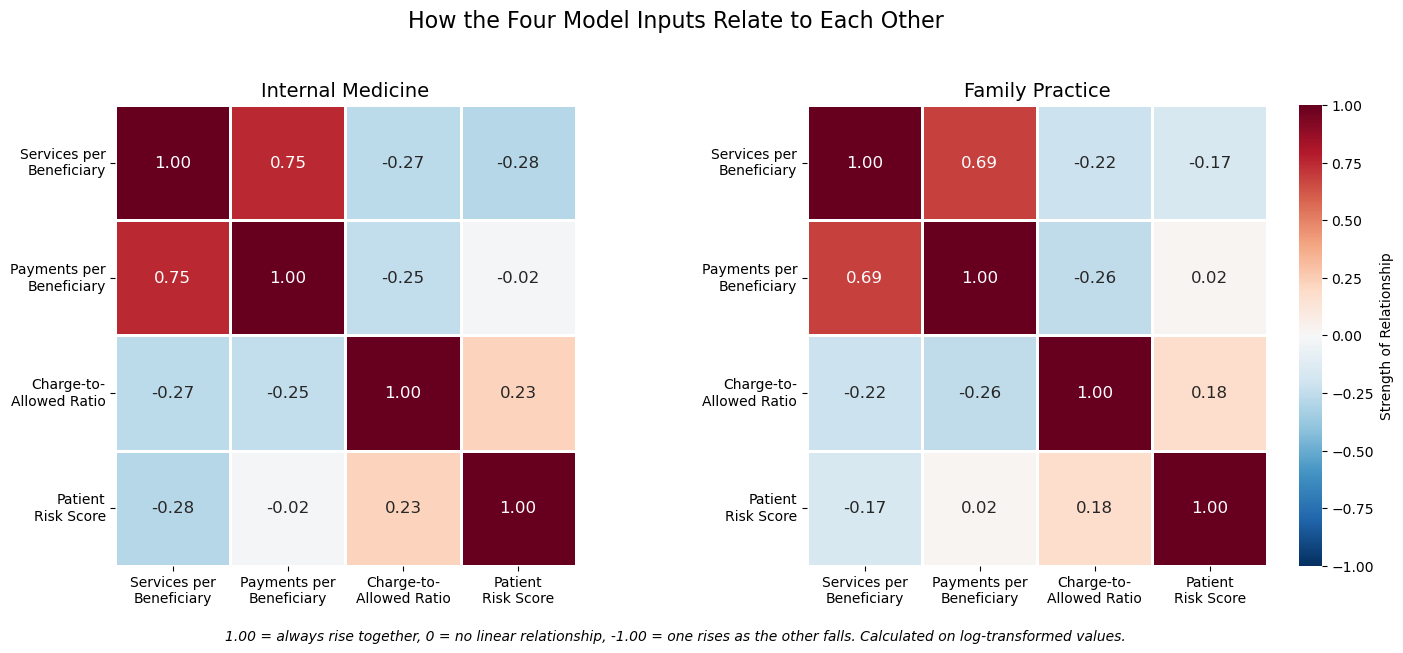

In [16]:
# Show how the four model inputs relate to each other within each specialty

labels = {'Log_Services_Per_Bene': 'Services per\nBeneficiary',
    'Log_Payments_Per_Bene': 'Payments per\nBeneficiary',
    'Log_Charge_Allowed_Ratio': 'Charge-to-\nAllowed Ratio',
    'Log_Bene_Avg_Risk_Scre': 'Patient\nRisk Score'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

for ax, specialty in zip(axes, ['Internal Medicine', 'Family Practice']):
    corr = medicare.loc[medicare['Rndrng_Prvdr_Type'] == specialty, list(labels)].corr()
    corr = corr.rename(index=labels, columns=labels)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
                square=True, linewidths=1, cbar=ax is axes[-1], ax=ax,
                annot_kws={'fontsize': 12}, cbar_kws={'label': 'Strength of Relationship'})
    ax.set_title(specialty, fontsize=14)
    ax.tick_params(axis='x', rotation=0)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('How the Four Model Inputs Relate to Each Other', fontsize=16)
fig.text(0.5, 0.01,
         '1.00 = always rise together, 0 = no linear relationship, -1.00 = one rises as the other falls. '
         'Calculated on log-transformed values.',
         ha='center', fontsize=10, style='italic')
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

**Assessment: Visual 2**

* **Services and payments:** Services per beneficiary and payments per beneficiary have the strongest relationship in both specialties (0.75 for Internal Medicine and 0.69 for Family Practice), meaning providers who bill more services per patient generally receive more payment per patient.
* **Charge ratios:** The charge-to-allowed ratio has weak negative relationships with services and payments (−0.22 to −0.27), indicating that higher charge-to-allowed ratios are weakly associated with fewer services and lower Medicare payments per beneficiary.
* **Risk scores:** Patient risk scores have almost no linear relationship with payments (−0.02 and 0.02) and only weak relationships with services and charge ratios (−0.28 to 0.23).
* **Specialty comparison:** The patterns are nearly identical in both specialties, with relationships slightly weaker in Family Practice.
* **Overall:** Because only services and payments are strongly related, charge ratios and patient risk scores contribute largely distinct information to the autoencoder, which may help distinguish unusual billing patterns.

## **Modeling**

### VISUAL 3 - Table of Billing Indicator Variation and Statistical Outliers by Specialty (Z-Score Baseline)

In [17]:
# Calculate z-scores within each specialty using the four log-transformed model inputs

model_inputs = [f'Log_{col}' for col in indicators] + ['Log_Bene_Avg_Risk_Scre']

for col in model_inputs:
    medicare[f'Z_{col}'] = medicare.groupby('Rndrng_Prvdr_Type')[col].transform(
        lambda x: (x - x.mean()) / x.std(ddof=0))

# Compare typical variation and extreme values for the three billing indicators

labels = {'Services_Per_Bene': 'Services per Beneficiary',
          'Payments_Per_Bene': 'Payments per Beneficiary',
          'Charge_Allowed_Ratio': 'Charge-to-Allowed Ratio'}

results = []

for specialty in ['Internal Medicine', 'Family Practice']:
    group = medicare[medicare['Rndrng_Prvdr_Type'] == specialty]
    for col in indicators:
        q1, median, q3 = group[col].quantile([0.25, 0.50, 0.75])
        extreme = group[f'Z_Log_{col}'].abs() > 3
        results.append({
            'Specialty': specialty,
            'Billing Indicator': labels[col],
            'Middle 50% Spread (% of Typical)': (q3 - q1) / median * 100,
            'Extreme Providers (%)': extreme.mean() * 100,
            'Number of Extreme Providers': extreme.sum(),
            'Providers with Unusually High Billing': (group[f'Z_Log_{col}'] > 3).sum()})

variation = pd.DataFrame(results)
display(variation.style.hide(axis='index').format({
    'Middle 50% Spread (% of Typical)': '{:.1f}%',
    'Extreme Providers (%)': '{:.2f}%',
    'Number of Extreme Providers': '{:,.0f}',
    'Providers with Unusually High Billing': '{:,.0f}'}))

Specialty,Billing Indicator,Middle 50% Spread (% of Typical),Extreme Providers (%),Number of Extreme Providers,Providers with Unusually High Billing
Internal Medicine,Services per Beneficiary,94.4%,1.60%,"1,496","1,496"
Internal Medicine,Payments per Beneficiary,72.7%,1.69%,"1,582",743
Internal Medicine,Charge-to-Allowed Ratio,54.5%,1.11%,"1,043","1,043"
Family Practice,Services per Beneficiary,108.0%,1.37%,"1,146","1,146"
Family Practice,Payments per Beneficiary,84.3%,1.95%,"1,635",369
Family Practice,Charge-to-Allowed Ratio,46.9%,2.10%,"1,754","1,754"


**Assessment: Visual 3**

* **Measures:** Middle 50% spread compares the range covered by the middle half of providers with the typical (median) value. Extreme providers are those more than 3 standard deviations above or below their specialty average, based on log-transformed billing values.
* **Services per beneficiary:** This indicator shows the greatest typical variation in both specialties, with a middle 50% spread of 94.4% for Internal Medicine and 108.0% for Family Practice. It also has the most providers with unusually high billing in Internal Medicine (1,496), and all of its extremes are on the high side.
* **Payments per beneficiary:** Payments show moderate typical variation (72.7% and 84.3%). Although this indicator has many extreme providers (1,582 and 1,635), most fall unusually low rather than high, leaving 743 Internal Medicine and 369 Family Practice providers with unusually high billing.
* **Charge-to-allowed ratio:** Charge ratios show the least typical variation (54.5% and 46.9%) but produce the most extremes in Family Practice (1,754, or 2.10%), all on the high side.
* **Overall:** Services per beneficiary varies the most among specialty peers overall, while charge-to-allowed ratios produce the most unusually high billers in Family Practice.

### TensorFlow Autoencoder

In [18]:
# Prepare the four model inputs separately for each specialty
# Reserve 20% for validation and standardize using training data only

tf.keras.utils.set_random_seed(42)
training_data = {}

for specialty in ['Internal Medicine', 'Family Practice']:
    group = medicare.loc[medicare['Rndrng_Prvdr_Type'] == specialty, model_inputs]
    train, val = train_test_split(group, test_size=0.20, random_state=42)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train).astype('float32')
    X_val = scaler.transform(val).astype('float32')

    training_data[specialty] = {'train': X_train, 'val': X_val, 'scaler': scaler}
    print(f'{specialty}: {len(X_train):,} training, {len(X_val):,} validation, {X_train.shape[1]} inputs')

Internal Medicine: 74,901 training, 18,726 validation, 4 inputs
Family Practice: 66,911 training, 16,728 validation, 4 inputs


In [19]:
# Build the autoencoder: compress the four inputs into two values, then rebuild all four

tf.config.experimental.enable_op_determinism()

def build_autoencoder(n_inputs):
    tf.keras.utils.set_random_seed(42)
    inputs = Input(shape=(n_inputs,))
    encoded = Dense(8, activation='relu')(inputs)
    bottleneck = Dense(2, activation='linear')(encoded)
    decoded = Dense(8, activation='relu')(bottleneck)
    outputs = Dense(n_inputs, activation='linear')(decoded)
    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='mse')
    return model

build_autoencoder(len(model_inputs)).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118 (472.00 B)

 Trainable params: 118 (472.00 B)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Train one autoencoder per specialty, stopping when validation loss stops improving

autoencoders, histories = {}, {}

for specialty, data in training_data.items():
    model = build_autoencoder(data['train'].shape[1])
    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, min_delta=0.0001,
                                               restore_best_weights=True)
    history = model.fit(data['train'], data['train'],
                        validation_data=(data['val'], data['val']),
                        epochs=300, batch_size=256, shuffle=True,
                        callbacks=[early_stop], verbose=0)
    autoencoders[specialty] = model
    histories[specialty] = history.history
    best = min(history.history['val_loss'])
    print(f"{specialty}: trained {len(history.history['loss'])} epochs, best validation loss {best:.4f}")

Internal Medicine: trained 197 epochs, best validation loss 0.1152
Family Practice: trained 120 epochs, best validation loss 0.1157


### VISUAL 4 - Line Chart of Autoencoder Training and Validation Loss by Specialty

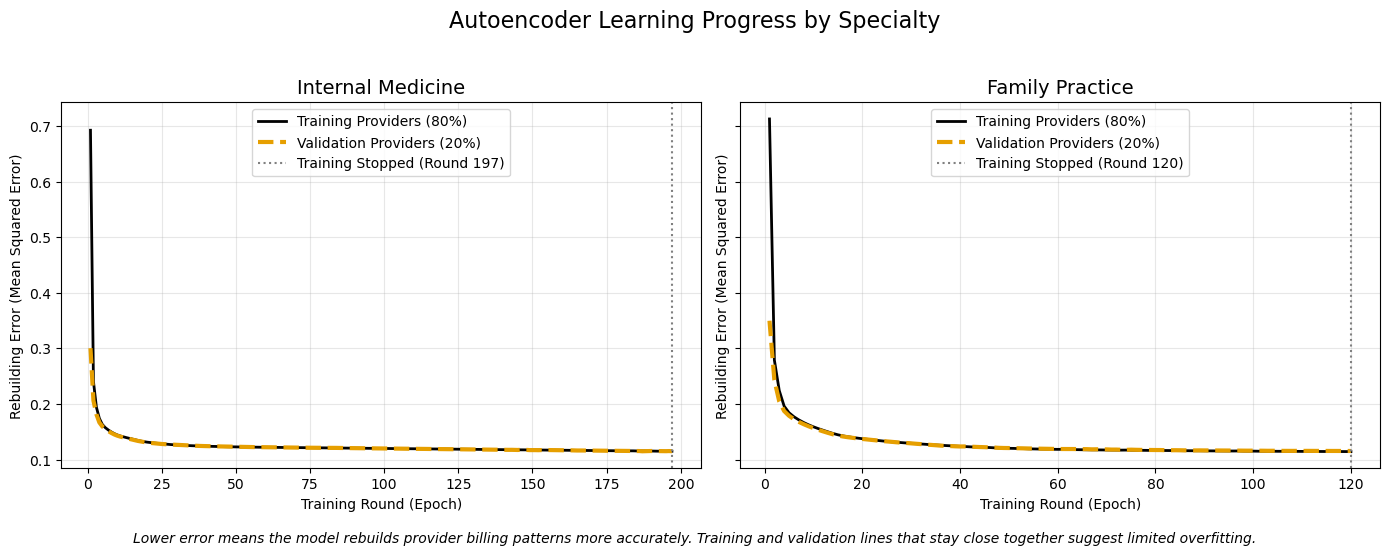

In [21]:
# Plot training and validation loss for each specialty's autoencoder

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for ax, (specialty, history) in zip(axes, histories.items()):
    rounds = range(1, len(history['loss']) + 1)
    ax.plot(rounds, history['loss'], color='black', linewidth=2,
            label='Training Providers (80%)')
    ax.plot(rounds, history['val_loss'], color='#E69F00', linewidth=3, linestyle='--',
            label='Validation Providers (20%)')
    ax.axvline(len(history['loss']), color='gray', linestyle=':', linewidth=1.5,
               label=f'Training Stopped (Round {len(history["loss"])})')
    ax.set_title(specialty, fontsize=14)
    ax.set_xlabel('Training Round (Epoch)')
    ax.set_ylabel('Rebuilding Error (Mean Squared Error)')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

fig.suptitle('Autoencoder Learning Progress by Specialty', fontsize=16)
fig.text(0.5, 0.01,
         'Lower error means the model rebuilds provider billing patterns more accurately. '
         'Training and validation lines that stay close together suggest limited overfitting.',
         ha='center', fontsize=10, style='italic')
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

**Assessment: Visual 4**

* **Learning speed:** Both autoencoders learned quickly, with training error falling from about 0.7 to below 0.2 within the first 10 training rounds.
* **Training length:** Training stopped automatically after 197 rounds for Internal Medicine and 120 for Family Practice, once validation error stopped meaningfully improving.
* **Validation error:** Both models achieved similar best validation errors of 0.1152 for Internal Medicine and 0.1157 for Family Practice, indicating comparable reconstruction performance.
* **Overall:** Training and validation errors remained closely aligned throughout both models' training, suggesting limited overfitting.

### Flag Providers with Unusual Billing Patterns

In [22]:
# Calculate each provider's reconstruction error using their specialty's autoencoder
# Flag providers in the top 1% of reconstruction error within each specialty

feature_names = {
    'Log_Services_Per_Bene': 'Services per Beneficiary',
    'Log_Payments_Per_Bene': 'Payments per Beneficiary',
    'Log_Charge_Allowed_Ratio': 'Charge-to-Allowed Ratio',
    'Log_Bene_Avg_Risk_Scre': 'Patient Risk Score'}

for specialty, data in training_data.items():
    rows = medicare['Rndrng_Prvdr_Type'] == specialty
    X = data['scaler'].transform(medicare.loc[rows, model_inputs]).astype('float32')
    rebuilt = autoencoders[specialty].predict(X, verbose=0)
    squared_errors = (X - rebuilt) ** 2

    medicare.loc[rows, 'Reconstruction_Error'] = squared_errors.mean(axis=1)
    for i, col in enumerate(model_inputs):
        medicare.loc[rows, f'Error_{col}'] = squared_errors[:, i]

    threshold = medicare.loc[rows, 'Reconstruction_Error'].quantile(0.99)
    medicare.loc[rows, 'AE_Flag'] = medicare.loc[rows, 'Reconstruction_Error'] >= threshold

    print(f"{specialty}: flag threshold {threshold:.3f}, "
          f"{int(medicare.loc[rows, 'AE_Flag'].sum()):,} of {rows.sum():,} providers flagged")

medicare['AE_Flag'] = medicare['AE_Flag'].astype(bool)

Internal Medicine: flag threshold 1.053, 937 of 93,627 providers flagged
Family Practice: flag threshold 0.974, 837 of 83,639 providers flagged


**Assessment: Flagged Providers**

* **Flag thresholds:** Providers were flagged when their reconstruction error met or exceeded 1.053 for Internal Medicine and 0.974 for Family Practice, the top 1% within each specialty. The 1% cutoff identifies the highest reconstruction errors. It does not establish that those providers billed improperly.
* **Flagged providers:** The autoencoder flagged 937 of 93,627 Internal Medicine providers and 837 of 83,639 Family Practice providers.

### VISUAL 5 - Scatter Plot Comparing Autoencoder Flags With Z-Score Outliers by Specialty

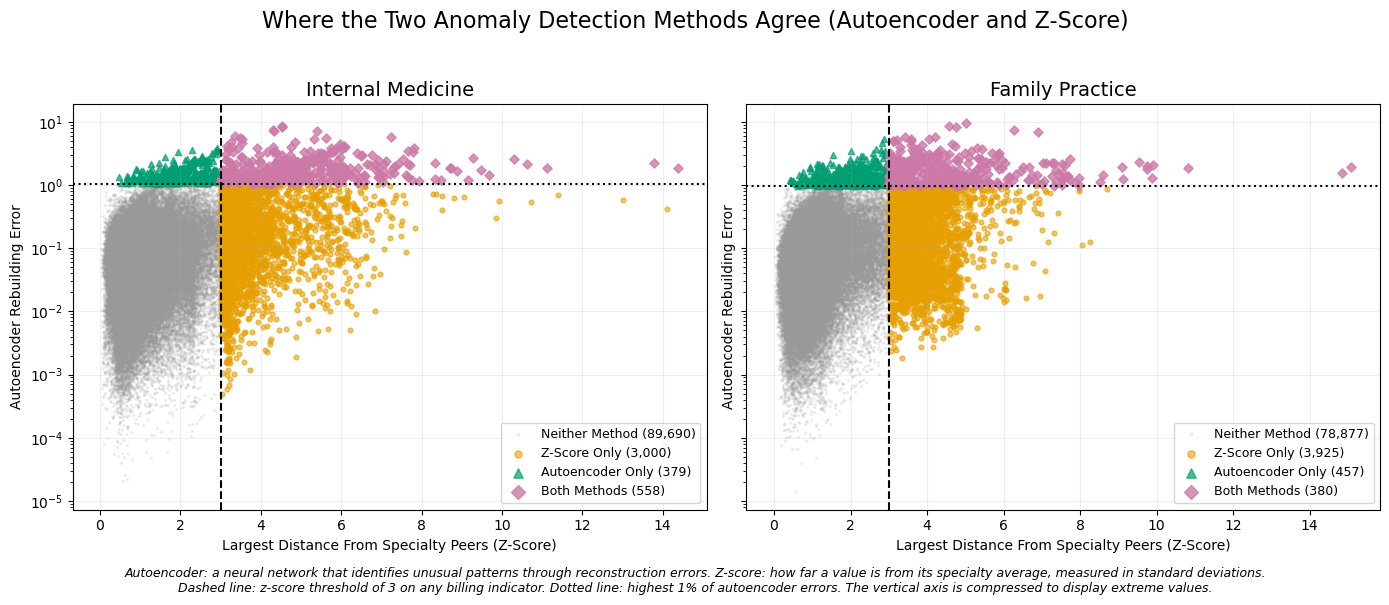

In [23]:
# Compare autoencoder and z-score flags for each specialty

billing_z = [f'Z_Log_{col}' for col in indicators]
medicare['Max_Abs_Z'] = medicare[billing_z].abs().max(axis=1)
medicare['Z_Flag'] = medicare['Max_Abs_Z'] > 3

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, specialty in zip(axes, ['Internal Medicine', 'Family Practice']):
    group = medicare[medicare['Rndrng_Prvdr_Type'] == specialty]
    ae, z = group['AE_Flag'], group['Z_Flag']

    categories = [('Neither Method', ~ae & ~z, '#999999', '.', 8, 0.12),
        ('Z-Score Only', ~ae & z, '#E69F00', 'o', 12, 0.6),
        ('Autoencoder Only', ae & ~z, '#009E73', '^', 20, 0.7),
        ('Both Methods', ae & z, '#CC79A7', 'D', 22, 0.8)]

    for label, mask, color, marker, size, alpha in categories:
        ax.scatter(group.loc[mask, 'Max_Abs_Z'],
                   group.loc[mask, 'Reconstruction_Error'],
                   color=color, marker=marker, s=size, alpha=alpha,
                   label=f'{label} ({mask.sum():,})', rasterized=True)

    threshold = group['Reconstruction_Error'].quantile(0.99)
    ax.axvline(3, color='black', linestyle='--', linewidth=1.5)
    ax.axhline(threshold, color='black', linestyle=':', linewidth=1.5)

    ax.set_yscale('log')
    ax.set_title(specialty, fontsize=14)
    ax.set_xlabel('Largest Distance From Specialty Peers (Z-Score)')
    ax.set_ylabel('Autoencoder Rebuilding Error')
    ax.legend(fontsize=9, loc='lower right', markerscale=1.5)
    ax.grid(alpha=0.2)

fig.suptitle('Where the Two Anomaly Detection Methods Agree (Autoencoder and Z-Score)',
             fontsize=16)
fig.text(0.5, 0.01,
         'Autoencoder: a neural network that identifies unusual patterns through reconstruction errors. '
         'Z-score: how far a value is from its specialty average, measured in standard deviations.\n'
         'Dashed line: z-score threshold of 3 on any billing indicator. Dotted line: highest 1% of autoencoder errors. '
         'The vertical axis is compressed to display extreme values.',
         ha='center', fontsize=9, style='italic')

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

**Assessment: Visual 5**

* **Internal Medicine:** Both methods flagged 558 providers, representing 59.6% of the 937 autoencoder flags. Another 379 were identified only by the autoencoder, while 3,000 were identified only by z-scores.
* **Family Practice:** Both methods flagged 380 providers, representing 45.4% of the 837 autoencoder flags. Another 457 were identified only by the autoencoder, compared with 3,925 identified only by z-scores.
* **Method differences:** The z-score method flagged considerably more providers in both specialties, while the autoencoder selected the highest 1% of reconstruction errors. Providers flagged only by the autoencoder did not exceed the z-score threshold on any single billing indicator, suggesting the model identifies unusual overall patterns that the billing-only method misses.
* **Overall:** The methods identify some of the same unusual providers but also produce substantially different results. The autoencoder considers patient risk scores alongside billing indicators, while the z-score baseline examines billing indicators only. Neither method establishes improper billing.

### VISUAL 6 - Bar Chart of Billing Indicators and Patient Risk Contributing to Autoencoder Flags

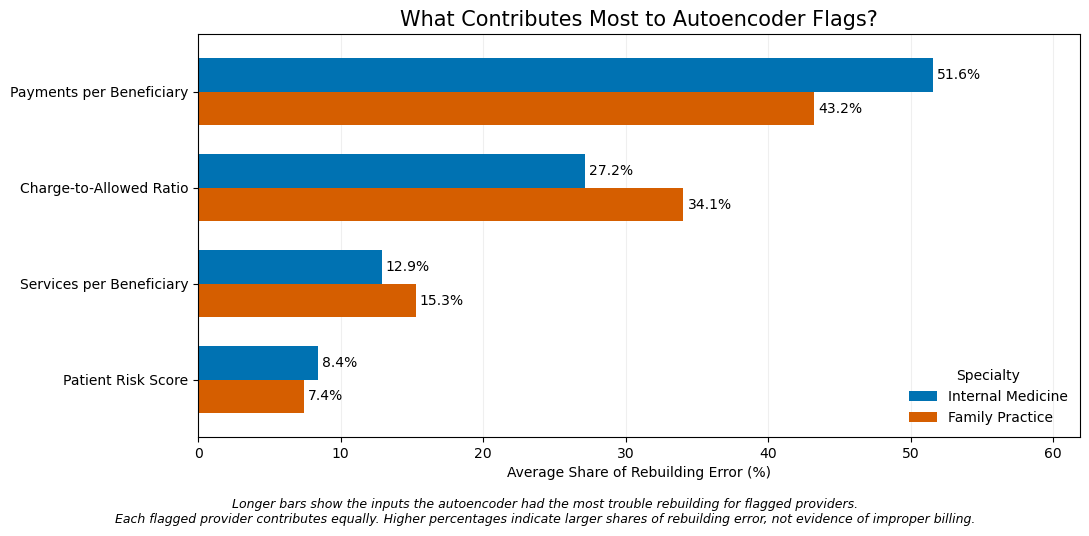

Specialty,Internal Medicine,Family Practice
Indicator,,
Payments per Beneficiary,51.60,43.20
Charge-to-Allowed Ratio,27.20,34.10
Services per Beneficiary,12.90,15.30
Patient Risk Score,8.40,7.40


In [24]:
# Show which inputs contribute most to autoencoder errors among flagged providers

error_cols = [f'Error_{col}' for col in model_inputs]
contributions = []

for specialty in ['Internal Medicine', 'Family Practice']:
    flagged = medicare.loc[
        (medicare['Rndrng_Prvdr_Type'] == specialty) & medicare['AE_Flag'],
        error_cols]
    shares = flagged.div(flagged.sum(axis=1), axis=0) * 100

    for col in model_inputs:
        contributions.append({
            'Indicator': feature_names[col].replace('\n', ' '),
            'Specialty': specialty,
            'Average Share (%)': shares[f'Error_{col}'].mean()})

contribution = pd.DataFrame(contributions).pivot(
    index='Indicator', columns='Specialty', values='Average Share (%)')
contribution = contribution.reindex(
    [feature_names[col].replace('\n', ' ') for col in model_inputs])

# Sort indicators from largest to smallest average contribution
contribution = contribution.loc[
    contribution.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 5.5))

contribution[['Internal Medicine', 'Family Practice']].plot(
    kind='barh', ax=ax, color=['#0072B2', '#D55E00'], width=0.7)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=10)

ax.invert_yaxis()
ax.set_xlim(0, contribution.max().max() * 1.2)
ax.set_xlabel('Average Share of Rebuilding Error (%)')
ax.set_ylabel('')
ax.set_title('What Contributes Most to Autoencoder Flags?', fontsize=15)
ax.legend(title='Specialty', frameon=False)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

fig.text(0.5, 0.01,
         'Longer bars show the inputs the autoencoder had the most trouble rebuilding for flagged providers.\n'
         'Each flagged provider contributes equally. Higher percentages indicate larger shares '
         'of rebuilding error, not evidence of improper billing.',
         ha='center', fontsize=9, style='italic')

plt.tight_layout(rect=[0, 0.06, 1, 0.97])
plt.show()
display(contribution[['Internal Medicine', 'Family Practice']].round(1))

**Assessment: Visual 6**

* **Payments per beneficiary:** Payments account for the largest share of rebuilding error among flagged providers, averaging 51.6% for Internal Medicine and 43.2% for Family Practice.
* **Charge-to-allowed ratio:** Charge ratios rank second, accounting for 27.2% of rebuilding error in Internal Medicine and 34.1% in Family Practice.
* **Services per beneficiary:** Services account for 12.9% and 15.3%, despite showing the greatest variation among providers in Visual 3.
* **Patient risk score:** Risk scores contribute the least, at 8.4% and 7.4%. The autoencoders had more difficulty rebuilding billing patterns than patient risk scores among flagged providers.
* **Overall:** Payments and charge ratios together account for approximately 79% of rebuilding error in Internal Medicine and 77% in Family Practice. These two indicators deserve particular attention when analysts review flagged providers, although unusual billing does not necessarily indicate improper payments.

## **Conclusion**

**Research Question 1:** After accounting for the number of beneficiaries, Internal Medicine and Family Practice providers showed relatively similar billing patterns. The 42% difference in median total Medicare payments narrowed to about 10% per beneficiary (`$232` versus `$212`), while typical services and charge ratios were also close. The largest difference was patient complexity, with median risk scores of 1.76 for Internal Medicine and 1.13 for Family Practice. Both specialties contained extreme billing values, with some extraordinary service volumes largely explained by drug billing units.

**Research Question 2:** Services per beneficiary showed the greatest typical variation among specialty peers, with a middle 50% spread of 94.4% for Internal Medicine and 108.0% for Family Practice. Charge-to-allowed ratios produced the most unusually high billers in Family Practice (1,754 providers), while most extreme payment values fell below, rather than above, specialty peers.

**Research Question 3:** The TensorFlow autoencoders flagged the top 1% of providers in each specialty, identifying 937 Internal Medicine and 837 Family Practice providers. Both models achieved similar validation errors of 0.1152 and 0.1157, respectively. Of those flagged, 558 Internal Medicine providers (59.6%) and 380 Family Practice providers (45.4%) were also identified by the z-score method. The remaining 379 and 457 autoencoder flags did not exceed the statistical threshold on any individual billing indicator, suggesting the autoencoders detected unusual overall patterns that the billing-only method missed.

**Research Question 4:** Payments per beneficiary and charge-to-allowed ratios accounted for approximately 79% of rebuilding error among flagged Internal Medicine providers and 77% among flagged Family Practice providers. These two indicators provide a starting point for analysts reviewing flagged providers. The results identify unusual billing patterns that warrant further examination, not evidence of improper billing.